Лабораторная работа №2. Визуализация данных и метод kNN

**Набор с Kaggle:** https://www.kaggle.com/datasets/arkhiplisitsa/instagram-top-accounts)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

VARIANT = 7
DATASET = 7
print("Вариант", VARIANT, "-> набор части 1 №", DATASET)

# общее оформление графиков: без верхней и правой рамки, бледная сетка
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11})
# цвета: синий, оранжевый, бирюзовый, жёлтый, розовый и нейтральный серый
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "magenta": "#e87ba4", "gray": "#8f8e88"}

Вариант 7 -> набор части 1 № 7


## Часть 1. Визуализация
**Набор № 7, CO2 Emissions** (Our World in Data): выбросы CO₂ по странам и источникам, млн т, до 2024 г.

**Задача варианта 7.** Оставьте только страны: строки с непустым `iso_code`, не начинающимся с `OWID` (так исключаются агрегаты «World», «Europe» и др.). Постройте горизонтальную столбчатую диаграмму 10 стран с наибольшими выбросами CO₂ в 2024 г. с подписями долей от мировых выбросов. Какую долю дают 10 стран вместе, какое место занимает Россия? Постройте динамику выбросов первых пяти стран с 1990 г.

*Контроль:* Китай — 12 289 млн т (31,8 %), США — 4904, Индия — 3193, Россия — 4-е место (1781 млн т); на 10 стран приходится 68,9 % мировых выбросов.

**Требования:** описать объект набора и проверить пропуски в используемых столбцах; ответить на вопросы числами; построить графики по правилам п. 1.2.4; сравнить числа с контрольными; записать 2–3 вывода.

In [ ]:
GH = "https://raw.githubusercontent.com/"
SB = GH + "mwaskom/seaborn-data/master/"
URLS = {
    1: SB + "flights.csv",
    2: SB + "healthexp.csv",
    3: SB + "seaice.csv",
    4: SB + "planets.csv",
    5: GH + "christophM/interpretable-ml-book/4fd7e3d61bc16f4f1e2d5492d5ecc60e247ba063/data/bike.csv",
    6: GH + "rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv",
    7: GH + "owid/co2-data/382ee6c662b0ece26e111f263b44c029afad7787/owid-co2-data.csv",
    8: GH + "datasets/global-temp/44571fe8c15e228c156bb19308e5ccc1e31cf9f7/data/monthly.csv",
    9: GH + "owid/energy-data/f8de88a4f6f9cab44f1cf606047cbd6c4414042c/owid-energy-data.csv",
    10: GH + "plotly/datasets/master/finance-charts-apple.csv",
}
df = pd.read_csv(URLS[DATASET])
print("Размер таблицы:", df.shape)
df[["country", "year", "iso_code", "population", "co2"]].head()

Размер таблицы: (50411, 79)


,country,year,iso_code,population,co2
0,Afghanistan,1750,AFG,2802560.0,NaN
1,Afghanistan,1751,AFG,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN


### 1.1. Объект набора и пропуски
Одна строка — одна страна (или регион/агрегат: «World», «Europe», «High-income countries» и т. п.) в один год. Нас интересуют столбцы `country`, `iso_code`, `year` и `co2` — годовые выбросы CO₂ в млн т.

In [ ]:
# страна = непустой iso_code, который не начинается с OWID
is_country = df["iso_code"].notna() & ~df["iso_code"].fillna("").str.startswith("OWID")
countries = df[is_country]
print("Строк всего:", len(df), "| из них страны:", len(countries), "| агрегаты:", (~is_country).sum())
print("Примеры исключённых агрегатов:", list(df.loc[~is_country, "country"].unique()[:8]))

c24 = countries[countries["year"] == 2024]
use = ["country", "iso_code", "year", "co2"]
print("\nПропуски в используемых столбцах (страны, 2024 г.):")
display(c24[use].isna().sum().to_frame("пропусков"))
print("Стран в 2024 г.:", len(c24), "| с известным co2:", c24["co2"].notna().sum())

Строк всего: 50411 | из них страны: 42480 | агрегаты: 7931
Примеры исключённых агрегатов: ['Africa', 'Africa (GCP)', 'Asia', 'Asia (GCP)', 'Asia (excl. China and India)', 'Central America (GCP)', 'Europe', 'Europe (GCP)']

Пропуски в используемых столбцах (страны, 2024 г.):


,пропусков
country,0
iso_code,0
year,0
co2,3


Стран в 2024 г.: 218 | с известным co2: 215


### 1.2. Десять крупнейших эмитентов в 2024 г.
Долю считаем от **мировых** выбросов — строки `World`. Сумма по странам немного меньше мирового итога, потому что в `World` входят ещё выбросы международной авиации и морских перевозок, которые не приписаны ни одной стране.

In [ ]:
world24 = df.loc[(df["country"] == "World") & (df["year"] == 2024), "co2"].item()
sum_countries = c24["co2"].sum()
print(f"Мировые выбросы 2024: {world24:,.0f} млн т; сумма по странам: {sum_countries:,.0f} млн т "
      f"({sum_countries / world24:.1%})".replace(",", " "))

top10 = c24.nlargest(10, "co2")[["country", "co2"]].reset_index(drop=True)
top10["доля мира, %"] = top10["co2"] / world24 * 100
top10["накопленная доля, %"] = top10["доля мира, %"].cumsum()
top10.index = top10.index + 1
display(top10.round(1))

share10 = top10["доля мира, %"].sum()
ranking = c24.dropna(subset=["co2"]).sort_values("co2", ascending=False).reset_index(drop=True)
rus_place = ranking.index[ranking["country"] == "Russia"][0] + 1
rus_co2 = ranking.loc[ranking["country"] == "Russia", "co2"].item()
print(f"10 стран вместе: {share10:.1f} % мировых выбросов")
print(f"Россия: {rus_place}-е место, {rus_co2:.0f} млн т ({rus_co2 / world24:.1%})")

Мировые выбросы 2024: 38 599 млн т; сумма по странам: 37 398 млн т (96.9%)


,country,co2,"доля мира, %","накопленная доля, %"
1,China,12289.0,31.8,31.8
2,United States,4904.1,12.7,44.5
3,India,3193.5,8.3,52.8
4,Russia,1780.5,4.6,57.4
5,Japan,961.9,2.5,59.9
6,Indonesia,812.2,2.1,62.0
7,Iran,792.6,2.1,64.1
8,Saudi Arabia,692.1,1.8,65.9
9,South Korea,583.7,1.5,67.4
10,Germany,572.3,1.5,68.9


10 стран вместе: 68.9 % мировых выбросов
Россия: 4-е место, 1781 млн т (4.6%)


### 1.3. Сравнение с контрольными значениями

In [ ]:
def get(c):
    return top10.loc[top10["country"] == c, "co2"].item()

check1 = pd.DataFrame({
    "получено": [round(get("China")), round(get("China") / world24 * 100, 1), round(get("United States")),
                 round(get("India")), rus_place, round(rus_co2), round(share10, 1)],
    "контроль": [12289, 31.8, 4904, 3193, 4, 1781, 68.9],
}, index=["Китай, млн т", "Китай, % мира", "США, млн т", "Индия, млн т",
          "Россия, место", "Россия, млн т", "10 стран, % мира"])
check1["совпадает"] = np.where(np.isclose(check1["получено"], check1["контроль"]), "да", "нет")
display(check1)
assert (check1["совпадает"] == "да").all()

,получено,контроль,совпадает
"Китай, млн т",12289.0,12289.0,да
"Китай, % мира",31.8,31.8,да
"США, млн т",4904.0,4904.0,да
"Индия, млн т",3193.0,3193.0,да
"Россия, место",4.0,4.0,да
"Россия, млн т",1781.0,1781.0,да
"10 стран, % мира",68.9,68.9,да


### 1.4. Графики

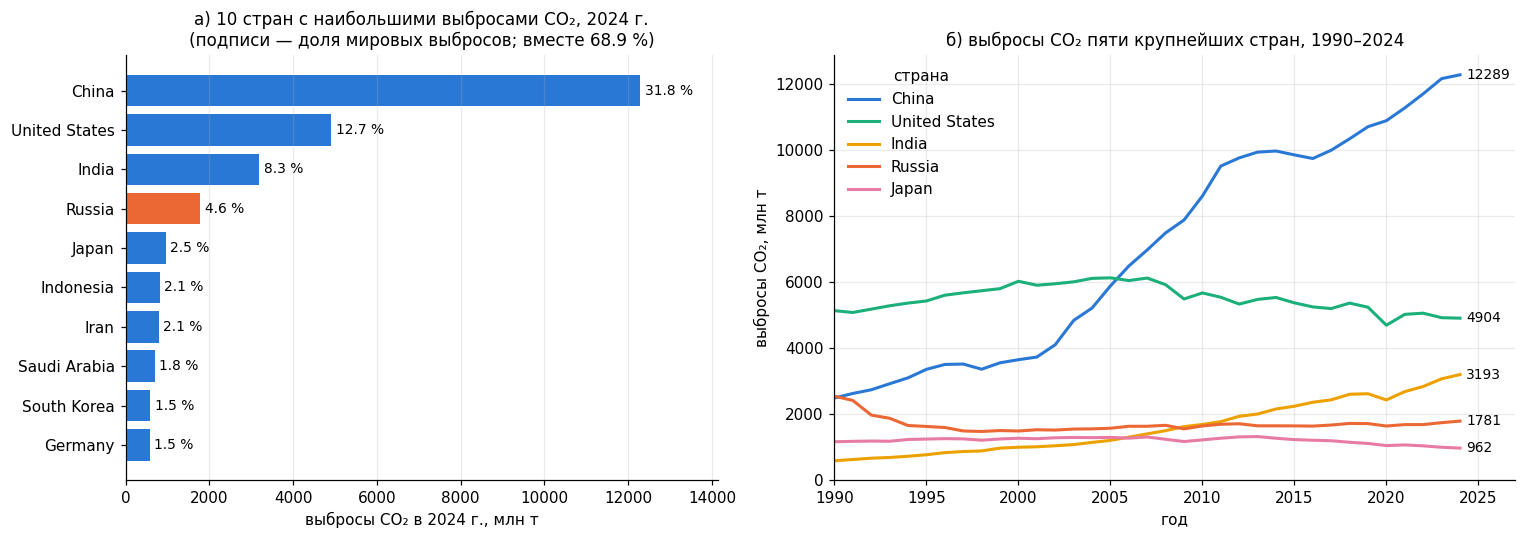

,"1990, млн т","2024, млн т","2024 / 1990, раз"
country,,,
China,2483.53,12289.04,4.95
United States,5131.76,4904.12,0.96
India,577.99,3193.48,5.53
Russia,2536.28,1780.52,0.70
Japan,1154.85,961.87,0.83


In [ ]:
top5 = list(top10["country"][:5])
wide = (countries[(countries["year"] >= 1990) & countries["country"].isin(top5)]
        .pivot(index="year", columns="country", values="co2")[top5])     # длинный -> широкий формат
colors5 = {"China": C["blue"], "United States": C["aqua"], "India": C["yellow"],
           "Russia": C["orange"], "Japan": C["magenta"]}

fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.15]})

# а) горизонтальные столбцы: сверху — наибольшее значение
t = top10.iloc[::-1]
bar_colors = [C["orange"] if c == "Russia" else C["blue"] for c in t["country"]]
bars = ax[0].barh(t["country"], t["co2"], color=bar_colors)
ax[0].bar_label(bars, labels=[f"{v:.1f} %" for v in t["доля мира, %"]], padding=3, fontsize=9)
ax[0].set(xlabel="выбросы CO₂ в 2024 г., млн т", xlim=(0, top10["co2"].max() * 1.15),
          title=f"а) 10 стран с наибольшими выбросами CO₂, 2024 г.\n(подписи — доля мировых выбросов; вместе {share10:.1f} %)")
ax[0].grid(axis="y", visible=False)

# б) динамика выбросов пяти крупнейших стран
for c in top5:
    ax[1].plot(wide.index, wide[c], color=colors5[c], lw=2, label=c)
    ax[1].annotate(f"{wide[c].iloc[-1]:.0f}", (wide.index[-1], wide[c].iloc[-1]),
                   xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax[1].set(xlabel="год", ylabel="выбросы CO₂, млн т", xlim=(1990, 2027),
          title="б) выбросы CO₂ пяти крупнейших стран, 1990–2024")
ax[1].legend(title="страна", frameon=False)
fig.tight_layout()
plt.show()

change = pd.DataFrame({"1990, млн т": wide.loc[1990], "2024, млн т": wide.loc[2024]})
change["2024 / 1990, раз"] = change["2024, млн т"] / change["1990, млн т"]
display(change.round(2))

### Выводы по части 1

1. **Выбросы CO₂ сильно сконцентрированы.** В 2024 г. на одну страну, Китай, приходится 31,8 % мировых выбросов (12 289 млн т) — больше, чем у следующих пяти стран вместе (США, Индия, Россия, Япония, Индонезия: 30,2 %); на 10 стран — 68,9 % (табл. п. 1.2, рис. а). Россия на 4-м месте: 1781 млн т, 4,6 % мира. Все числа совпали с контрольными (п. 1.3).
2. **У крупнейших стран противоположная динамика** (рис. б, табл. под ним). С 1990 по 2024 г. выбросы Китая выросли в 4,95 раза, Индии — в 5,53 раза, а у США снизились на 4 %, у Японии — на 17 %, у России — на 30 % (2536 → 1781 млн т, основное падение пришлось на 1990-е). Около 2006 г. Китай обогнал США и с тех пор увеличил отрыв.
3. **Доля от мира зависит от того, что считать «миром».** Сумма выбросов всех стран составляет 96,9 % строки `World`: остальное — международная авиация и морские перевозки, не приписанные ни одной стране. Поэтому доли считаются от `World`, а не от суммы по странам; иначе доля Китая вышла бы 32,9 %.

## Часть 2. Метод k ближайших соседей
**Задача варианта 7.** Penguins, 4 числовых признака и вид (`pd.get_dummies`), класс — пол (MALE — 1). Метрика: евклидова; веса: равные; масштабирование: `StandardScaler`. Сравните точность при k = 5 с признаками вида и без них. Постройте ящики с усами массы тела по полу отдельно для каждого вида. Почему признаки вида почти не влияют на результат?

*Контроль:* при k = 5 accuracy на валидации 0,851; лучшее k = 14 (0,925), на тесте 0,910; константный прогноз — 0,507; без признаков вида при k = 5 — также 0,851.

**Порядок выполнения:**
1. Загрузить и подготовить данные (табл. 4: `penguins.csv`, удалить строки с пропусками, признаки `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`), выполнить разбиение, вывести размеры выборок и распределение классов. Вычислить качество константного прогноза на тестовой выборке.
2. Написать функцию `knn_predict(X_train, y_train, X_new, k)` с метрикой и весами варианта, без цикла по объектам `X_new`.
3. Сравнить её прогнозы на валидации при k = 5 с `KNeighborsClassifier` (`algorithm="brute"`), вывести долю совпадений.
4. Для k = 1…25 вычислить accuracy на обучающей и валидационной выборках, построить оба графика на одних осях; выбрать k с наилучшей точностью на валидации (при равенстве — наименьшее).
5. Обучить модель с выбранным k и один раз оценить её на тесте, сравнить с константным прогнозом.
6. Выполнить дополнительное задание.

### 2.1. Подготовка данных, разбиение, константный прогноз

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

peng = pd.read_csv(SB + "penguins.csv")
print("Строк до удаления пропусков:", len(peng))
peng = peng.dropna().reset_index(drop=True)
print("После dropna():", len(peng))

NUM = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X_df = pd.concat([peng[NUM], pd.get_dummies(peng["species"], prefix="species", dtype=float)], axis=1)
X = X_df.to_numpy(dtype=float)
y = (peng["sex"] == "MALE").astype(int).to_numpy()      # MALE -> 1, FEMALE -> 0
print("Признаки:", list(X_df.columns))

CLASSIFICATION = True
strat = y if CLASSIFICATION else None
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=strat)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, random_state=42,
    stratify=y_tmp if CLASSIFICATION else None)

sizes = pd.DataFrame({
    "объектов": [len(y_train), len(y_val), len(y_test)],
    "самок (0)": [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "самцов (1)": [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()],
}, index=["обучающая", "валидационная", "тестовая"])
display(sizes)

# масштабирование: параметры только по обучающей выборке
scaler = StandardScaler().fit(X_train)
Z_train, Z_val, Z_test = (scaler.transform(a) for a in (X_train, X_val, X_test))

# константный прогноз: самый частый класс обучающей выборки
const_class = np.bincount(y_train).argmax()
acc_const = (y_test == const_class).mean()
print(f"Константный прогноз: всегда класс {const_class} (самец); accuracy на тесте = {acc_const:.3f}")

Строк до удаления пропусков: 344
После dropna(): 333
Признаки: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'species_Adelie', 'species_Chinstrap', 'species_Gentoo']


,объектов,самок (0),самцов (1)
обучающая,199,99,100
валидационная,67,33,34
тестовая,67,33,34


Константный прогноз: всегда класс 1 (самец); accuracy на тесте = 0.507


### 2.2. Собственная реализация kNN
Матрица расстояний считается транслированием, как в ЛР № 1: у новых объектов добавляется ось посередине, у обучающих — в начале, разность имеет форму (m, ℓ, d). Цикл есть только по классам (их два), по объектам цикла нет. При равенстве голосов `argmax` выбирает первый класс (0) — так же поступает scikit-learn.

In [ ]:
def knn_predict(X_train, y_train, X_new, k):
    # Прогноз kNN для всех объектов X_new без цикла по объектам.
    # Метрика — евклидова, веса — равные (голосование большинством).
    diff = X_new[:, None, :] - X_train[None, :, :]          # (m, l, d)
    D = np.sqrt((diff ** 2).sum(axis=-1))                    # (m, l) — матрица расстояний
    idx = np.argsort(D, axis=1, kind="stable")[:, :k]        # (m, k) — номера k ближайших
    y_nb = y_train[idx]                                      # (m, k) — ответы соседей
    classes = np.unique(y_train)
    votes = np.stack([(y_nb == c).sum(axis=1) for c in classes], axis=1)   # (m, число классов)
    return classes[votes.argmax(axis=1)]

### 2.3. Проверка: сравнение со scikit-learn при k = 5

In [ ]:
pred_my = knn_predict(Z_train, y_train, Z_val, 5)
sk = KNeighborsClassifier(n_neighbors=5, metric="euclidean", weights="uniform", algorithm="brute")
pred_sk = sk.fit(Z_train, y_train).predict(Z_val)

print(f"Доля совпадающих прогнозов: {(pred_my == pred_sk).mean():.3f} "
      f"({(pred_my == pred_sk).sum()} из {len(pred_my)})")
print(f"accuracy на валидации при k = 5: своя функция {(pred_my == y_val).mean():.3f}, "
      f"sklearn {(pred_sk == y_val).mean():.3f} (контроль 0,851)")

Доля совпадающих прогнозов: 1.000 (67 из 67)
accuracy на валидации при k = 5: своя функция 0.851, sklearn 0.851 (контроль 0,851)


### 2.4. Подбор k = 1…25

Лучшее k = 14, accuracy на валидации = 0.925 (контроль: k = 14, 0,925)


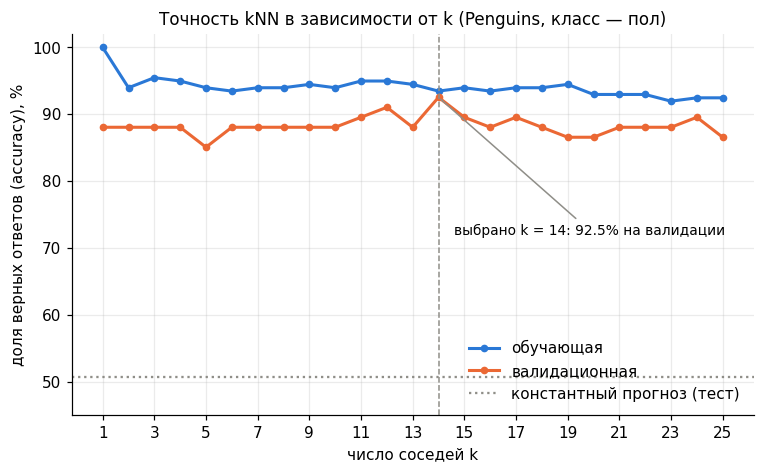

In [ ]:
ks = np.arange(1, 26)
acc_train = np.array([(knn_predict(Z_train, y_train, Z_train, k) == y_train).mean() for k in ks])
acc_val = np.array([(knn_predict(Z_train, y_train, Z_val, k) == y_val).mean() for k in ks])
best_k = int(ks[np.argmax(acc_val)])      # argmax берёт первый максимум, т. е. наименьшее k
print(f"Лучшее k = {best_k}, accuracy на валидации = {acc_val.max():.3f} (контроль: k = 14, 0,925)")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ks, acc_train * 100, "-o", ms=4, color=C["blue"], lw=2, label="обучающая")
ax.plot(ks, acc_val * 100, "-o", ms=4, color=C["orange"], lw=2, label="валидационная")
ax.axhline(acc_const * 100, color=C["gray"], ls=":", label="константный прогноз (тест)")
ax.axvline(best_k, color=C["gray"], ls="--", lw=1)
ax.annotate(f"выбрано k = {best_k}: {acc_val.max():.1%} на валидации", (best_k, acc_val.max() * 100),
            xytext=(best_k + 0.6, 72), textcoords="data", fontsize=9,
            arrowprops=dict(arrowstyle="-", color=C["gray"]))
ax.set(xlabel="число соседей k", ylabel="доля верных ответов (accuracy), %", ylim=(45, 102),
       xticks=ks[::2], title="Точность kNN в зависимости от k (Penguins, класс — пол)")
ax.legend(frameon=False, loc="lower right")
plt.show()

### 2.5. Итоговая оценка на тестовой выборке

In [ ]:
pred_test = knn_predict(Z_train, y_train, Z_test, best_k)
acc_test = (pred_test == y_test).mean()
acc_test_sk = (KNeighborsClassifier(n_neighbors=best_k, algorithm="brute")
               .fit(Z_train, y_train).predict(Z_test) == y_test).mean()

result = pd.DataFrame({
    "получено": [best_k, round(acc_val[ks == 5][0], 3), round(acc_val.max(), 3), round(acc_test, 3), round(acc_const, 3)],
    "контроль": [14, 0.851, 0.925, 0.910, 0.507],
}, index=["выбранное k", "accuracy, валидация, k = 5", "accuracy, валидация, лучшее k",
          "accuracy, тест, лучшее k", "константный прогноз, тест"])
display(result)
print(f"sklearn на тесте при k = {best_k}: {acc_test_sk:.3f}")
print(f"Модель лучше константного прогноза на {(acc_test - acc_const) * 100:.1f} процентных пункта")

,получено,контроль
выбранное k,14.000,14.000
"accuracy, валидация, k = 5",0.851,0.851
"accuracy, валидация, лучшее k",0.925,0.925
"accuracy, тест, лучшее k",0.910,0.910
"константный прогноз, тест",0.507,0.507


sklearn на тесте при k = 14: 0.910
Модель лучше константного прогноза на 40.3 процентных пункта


### 2.6. Дополнительное задание
**а) Точность при k = 5 с признаками вида и без них.** Масштабирование для набора без вида обучается заново, тоже только по обучающей выборке (разбиение то же — те же строки).

In [ ]:
num_cols = [X_df.columns.get_loc(c) for c in NUM]        # первые 4 столбца — числовые признаки
sc_num = StandardScaler().fit(X_train[:, num_cols])
Zn_train, Zn_val, Zn_test = (sc_num.transform(a[:, num_cols]) for a in (X_train, X_val, X_test))

acc_val_nosp = np.array([(knn_predict(Zn_train, y_train, Zn_val, k) == y_val).mean() for k in ks])
best_k_nosp = int(ks[np.argmax(acc_val_nosp)])
acc_test_nosp = (knn_predict(Zn_train, y_train, Zn_test, best_k_nosp) == y_test).mean()

compare = pd.DataFrame({
    "accuracy, валидация, k = 5": [acc_val[ks == 5][0], acc_val_nosp[ks == 5][0]],
    "лучшее k": [best_k, best_k_nosp],
    "accuracy, валидация, лучшее k": [acc_val.max(), acc_val_nosp.max()],
    "accuracy, тест, лучшее k": [acc_test, acc_test_nosp],
}, index=["4 признака + вид", "только 4 признака"])
display(compare.round(3))

,"accuracy, валидация, k = 5",лучшее k,"accuracy, валидация, лучшее k","accuracy, тест, лучшее k"
4 признака + вид,0.851,14,0.925,0.910
только 4 признака,0.851,14,0.910,0.896


**б) Ящики с усами массы тела по полу для каждого вида**

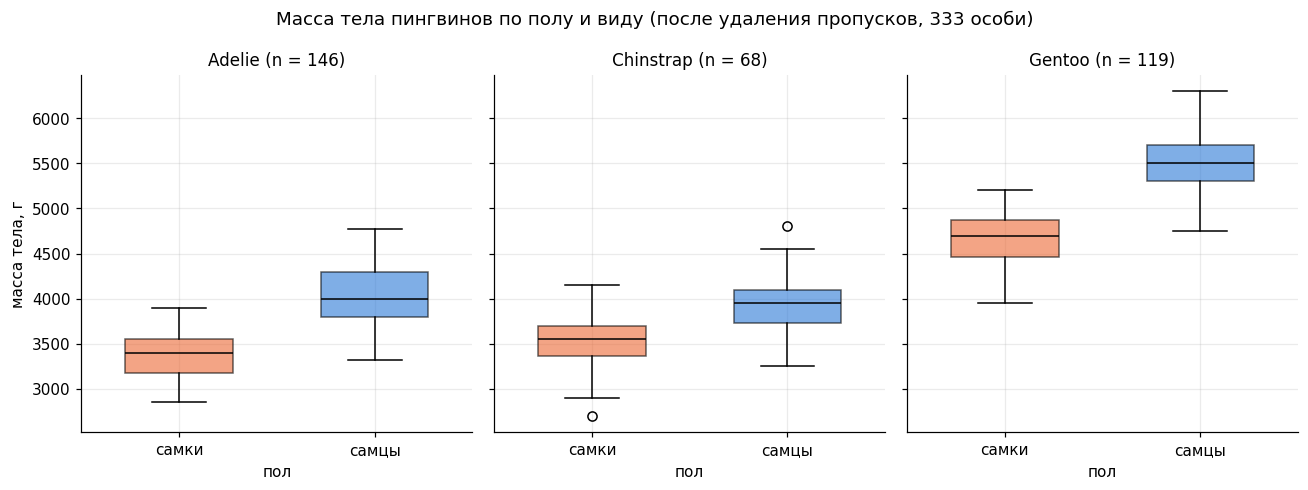

sex,"медиана самок, г","медиана самцов, г"
species,,
Adelie,3400.0,4000.0
Chinstrap,3550.0,3950.0
Gentoo,4700.0,5500.0


In [ ]:
species_list = ["Adelie", "Chinstrap", "Gentoo"]
fig, ax = plt.subplots(1, 3, figsize=(12, 4.5), sharey=True)
for a, sp in zip(ax, species_list):
    part = peng[peng["species"] == sp]
    data = [part.loc[part["sex"] == "FEMALE", "body_mass_g"], part.loc[part["sex"] == "MALE", "body_mass_g"]]
    bp = a.boxplot(data, tick_labels=["самки", "самцы"], patch_artist=True, widths=0.55,
                   medianprops=dict(color="black"))
    for patch, col in zip(bp["boxes"], [C["orange"], C["blue"]]):
        patch.set(facecolor=col, alpha=0.6)
    a.set_title(f"{sp} (n = {len(part)})")
    a.set_xlabel("пол")
ax[0].set_ylabel("масса тела, г")
fig.suptitle("Масса тела пингвинов по полу и виду (после удаления пропусков, 333 особи)")
fig.tight_layout()
plt.show()

mass = peng.pivot_table(index="species", columns="sex", values="body_mass_g", aggfunc="median")
display(mass.rename(columns={"FEMALE": "медиана самок, г", "MALE": "медиана самцов, г"}))

**в) Почему признаки вида почти не влияют на результат?** Проверим два факта: (1) вид однозначно определяется по четырём размерам тела; (2) ближайшие соседи по четырём размерам и так оказываются того же вида.

In [ ]:
sp_all = peng["species"].to_numpy()
_, _, sp_tmp, sp_test = train_test_split(X, sp_all, test_size=0.2, random_state=42, stratify=y)
_, _, sp_train, sp_val = train_test_split(X_tmp, sp_tmp, test_size=0.25, random_state=42, stratify=y_tmp)

# (1) kNN предсказывает вид по 4 числовым признакам
acc_species = (knn_predict(Zn_train, sp_train, Zn_val, 5) == sp_val).mean()
print(f"(1) kNN (k = 5) определяет вид по 4 размерам с точностью {acc_species:.3f}")

# (2) доля из 5 ближайших соседей (без признаков вида), которые того же вида
D = np.sqrt(((Zn_val[:, None, :] - Zn_train[None, :, :]) ** 2).sum(axis=-1))
nb = np.argsort(D, axis=1, kind="stable")[:, :5]
same = (sp_train[nb] == sp_val[:, None])
print(f"(2) соседей того же вида: {same.mean():.1%}; объектов, у которых все 5 соседей своего вида: {same.all(axis=1).mean():.1%}")

(1) kNN (k = 5) определяет вид по 4 размерам с точностью 1.000
(2) соседей того же вида: 98.2%; объектов, у которых все 5 соседей своего вида: 94.0%


**Ответ.** Признаки вида почти ничего не добавляют, потому что **информация о виде уже содержится в четырёх размерах тела**:
- по четырём числовым признакам kNN определяет вид на валидации с точностью 1,000 (п. «в», факт 1);
- 98,2 % ближайших соседей объекта (без признаков вида) — того же вида, у 94 % объектов все 5 соседей своего вида (факт 2). Признаки вида не меняют набор соседей, поэтому при k = 5 точность одинакова — 0,851 в обоих случаях, как и в контроле.

При этом вид для определения пола **нужен**, просто он и так «виден» по размерам. На ящиках с усами (п. «б») внутри каждого вида самцы тяжелее самок (медианы 4000 против 3400 г у Adelie, 3950 против 3550 г у Chinstrap, 5500 против 4700 г у Gentoo), но между видами массы перекрываются: самка Gentoo (медиана 4700 г) тяжелее самца Adelie (4000 г). Поэтому вывод «тяжёлый — значит самец» верен только среди особей одного вида, а kNN как раз сравнивает объект с похожими на него особями, то есть с особями того же вида.

При подборе k признаки вида дают небольшой выигрыш: 0,925 против 0,910 на валидации и 0,910 против 0,896 на тесте (лучшее k = 14 в обоих случаях) — это 1 объект из 67, то есть в пределах случайного разброса.

**Итог части 2.** Собственная функция совпала со scikit-learn на 100 % прогнозов. При k = 1 точность на обучающей выборке 100 % (каждый объект — ближайший сосед самому себе), а на валидации 88 % — переобучение. Выбрано k = 14: точность 0,925 на валидации и 0,910 на тесте против 0,507 у константного прогноза; все значения совпали с контрольными.

## Часть 3. Исследование набора с Kaggle
**Обязательный тип графика для варианта 7:** наложенные гистограммы или оценки плотности для нескольких групп.

**Требования:** 1) описать набор: источник, объект, признаки, размер, пропуски; при необходимости очистить данные и привести типы; 2) сформулировать три содержательных вопроса; 3) ответить на них не менее чем тремя графиками разных типов, один — обязательного типа, не менее двух — по преобразованным данным; 4) записать 4–6 выводов, опирающихся на числа и графики, и отметить, какие выводы требуют дополнительной проверки.

### 3.1. Описание набора
**Источник:** [Most Followed Instagram Accounts Daily](https://www.kaggle.com/datasets/arkhiplisitsa/instagram-top-accounts) - публичные числа подписчиков 2000 крупнейших аккаунтов Instagram, которые собираются каждый день. В архиве два файла: `latest` — последний снимок по каждому аккаунту и `daily` — вся история наблюдений; работа с `daily`.

In [ ]:
import kagglehub, pathlib

path = pathlib.Path(kagglehub.dataset_download("arkhiplisitsa/instagram-top-accounts"))
print(sorted(p.name for p in path.iterdir()))
daily_file = next(p for p in sorted(path.glob("*.csv")) if "daily" in p.name or "all" in p.name)
print("Читаем:", daily_file.name)

# sep=None: разделитель определяется автоматически
ig_raw = pd.read_csv(daily_file, sep=None, engine="python", encoding="utf-8-sig")
print("Размер таблицы:", ig_raw.shape)
display(ig_raw.head())
print(ig_raw.dtypes)

100%|██████████| 1.34M/1.34M [00:00<00:00, 85.7MB/s]

Extracting files...
['daily.csv', 'latest.csv']
Читаем: daily.csv


Размер таблицы: (37256, 10)


,date,username,followers,name,category,country,type,rank,also_in,countries
0,2026-09-25,433,79654283,433,Media,NL,org,56,NaN,NL
1,2026-09-25,9gag,51955772,9GAG: Go Fun The World,Media,HK,org,133,NaN,HK
2,2026-09-25,adele,55957481,Adele,Music,GB,person,118,NaN,GB
3,2026-09-25,agustd,55091406,SUGA of BTS 민윤기,Music,KR,person,121,NaN,KR
4,2026-09-25,akshaykumar,64955179,Akshay Kumar,Film & TV,IN,person,88,NaN,IN


date         object
username     object
followers     int64
name         object
category     object
country      object
type         object
rank          int64
also_in      object
countries    object
dtype: object


**Приведение типов.** Столбец `date` читается как текст. В оригинальном файле даты стоят в стандартном формате. Если же файл открыть и сохранить в русском Excel, даты превращаются в строки вида `25-сен-26`, а американские даты «месяц/день» до 12-го числа Excel читает наоборот: 1 октября становится «10 января», 2 октября — «10 февраля» и т. д.

Набор пополняется каждый день, поэтому для воспроизводимости ограничиваем период датой `END` — последним днём на момент выполнения работы.

In [ ]:
END = pd.Timestamp("2026-10-30")      # фиксируем период, чтобы числа в выводах не менялись
ig = ig_raw.copy()
ig["date"] = pd.to_datetime(ig["date"])
ig = ig[ig["date"] <= END]

print("Период:", ig["date"].min().date(), "—", ig["date"].max().date(),
      f"({ig['date'].nunique()} дней)")
print("Строк:", len(ig), "| аккаунтов:", ig["username"].nunique())
print("Повторов пары (username, date):", ig.duplicated(["username", "date"]).sum())
print("\nПропуски:")
display(pd.DataFrame({"пропусков": ig.isna().sum(), "доля, %": (ig.isna().mean() * 100).round(1)}))
print("Строк с followers = 0 (аккаунт скрыт или удалён):", (ig["followers"] == 0).sum())
display(ig["category"].value_counts().to_frame("строк"))

Период: 2026-09-25 — 2026-10-30 (36 дней)
Строк: 37256 | аккаунтов: 11997
Повторов пары (username, date): 0

Пропуски:


,пропусков,"доля, %"
date,0,0.0
username,0,0.0
followers,0,0.0
name,0,0.0
category,0,0.0
country,858,2.3
type,0,0.0
rank,0,0.0
also_in,36241,97.3
countries,858,2.3


Строк с followers = 0 (аккаунт скрыт или удалён): 6


,строк
category,
Sports,10252
Music,9318
Film & TV,9264
Public figures,2599
Brands & Companies,2141
Media,1136
Fashion & beauty,1049
Creators,805
Other,692


**Что является объектом.** Одна строка — одно наблюдение аккаунта в один день: `date` — дата, `username` и `name` — логин и имя, `followers` — число подписчиков, `category` — категория (Sports, Music, Film & TV, Brands & Companies и др.), `country` и `countries` — основная страна и все связанные страны, `type` — человек (`person`) или организация (`org`), `rank` — место в рейтинге по последнему снимку (у аккаунта одно значение), `also_in` — дополнительная категория.

**Пропуски и очистка.** `also_in` пуст почти всегда — у большинства аккаунтов нет второй категории, это не ошибка. `country` не указана для небольшой доли аккаунтов (международные бренды, фан-страницы) — в анализе по странам такие аккаунты не участвуют. Строки с `followers = 0` — скрытые или удалённые аккаунты, их удаляем.

**Особенность сбора.** Каждый день обновляется только часть аккаунтов (около 800), а 2 октября был полный обход (10 тыс. строк). Поэтому у разных аккаунтов разное число наблюдений.

In [ ]:
ig = ig[ig["followers"] > 0].sort_values(["username", "date"])
per_day = ig.groupby("date").size()
obs = ig.groupby("username")["date"].nunique()
print("Наблюдений за день: медиана", int(per_day.median()), "| максимум", per_day.max(), "в", per_day.idxmax().date())
print("Наблюдений на аккаунт:", obs.describe()[["mean", "50%", "max"]].round(1).to_dict())

Наблюдений за день: медиана 804 | максимум 10000 в 2026-10-02
Наблюдений на аккаунт: {'mean': 3.1, '50%': 1.0, 'max': 36.0}


### 3.2. Вопросы
1. **Как менялось число подписчиков у крупнейших аккаунтов в течение октября 2026 г. и одинаково ли оно менялось у людей и организаций?**
2. **Чем отличается скорость роста аудитории у аккаунтов разных категорий** (спорт, музыка, кино и ТВ, бренды)?
3. **Связана ли скорость роста с размером аккаунта:** растут ли крупные аккаунты медленнее мелких?

### 3.3. Вопрос 1: динамика в октябре
Чтобы сравнивать одни и те же аккаунты каждый день, берём аккаунты, которые наблюдались **каждый день со 2 по 30 октября**. Для каждого считаем изменение числа подписчиков относительно 2 октября в процентах, затем по каждому дню берём медиану по людям и по организациям (и межквартильный интервал).

Аккаунтов в панели: 424 {'person': 339, 'org': 85}


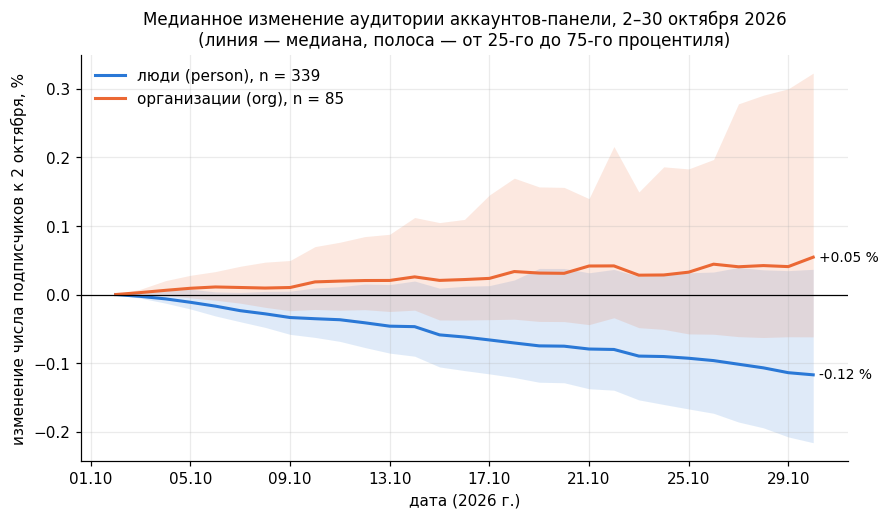

,"25-й процентиль, %","медиана, %","75-й процентиль, %"
люди (person),-0.216,-0.117,0.037
организации (org),-0.062,0.054,0.323


Доля аккаунтов, у которых к 30 октября подписчиков стало больше: {'люди (person)': '29%', 'организации (org)': '61%'}


In [ ]:
START = pd.Timestamp("2026-10-02")
oct_ = ig[ig["date"] >= START]
wide_f = oct_.pivot(index="date", columns="username", values="followers")       # дни × аккаунты
n_days = len(wide_f)
panel = wide_f.columns[wide_f.notna().sum() >= n_days - 1]                     # пропущено не более 1 дня
wide_f = wide_f[panel].interpolate(limit_area="inside").ffill()
change_pct = (wide_f / wide_f.iloc[0] - 1) * 100                                 # % к 2 октября

acc_type = ig.groupby("username")["type"].first()
groups = {"люди (person)": C["blue"], "организации (org)": C["orange"]}
codes = {"люди (person)": "person", "организации (org)": "org"}
print("Аккаунтов в панели:", len(panel), acc_type[panel].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(9, 4.8))
summary_q1 = {}
for label, col in groups.items():
    cols = [u for u in panel if acc_type[u] == codes[label]]
    q = change_pct[cols].quantile([0.25, 0.5, 0.75], axis=1).T
    ax.fill_between(q.index, q[0.25], q[0.75], color=col, alpha=0.15, lw=0)
    ax.plot(q.index, q[0.5], color=col, lw=2, label=f"{label}, n = {len(cols)}")
    ax.annotate(f"{q[0.5].iloc[-1]:+.2f} %", (q.index[-1], q[0.5].iloc[-1]), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=9)
    summary_q1[label] = q.iloc[-1]
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="дата (2026 г.)", ylabel="изменение числа подписчиков к 2 октября, %",
       title="Медианное изменение аудитории аккаунтов-панели, 2–30 октября 2026\n(линия — медиана, полоса — от 25-го до 75-го процентиля)")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d.%m"))
ax.legend(frameon=False, loc="upper left")
plt.show()

display(pd.DataFrame(summary_q1).T.rename(columns={0.25: "25-й процентиль, %", 0.5: "медиана, %", 0.75: "75-й процентиль, %"}).round(3))
share_up = {lab: (change_pct.iloc[-1][[u for u in panel if acc_type[u] == codes[lab]]] > 0).mean() for lab in groups}
print("Доля аккаунтов, у которых к 30 октября подписчиков стало больше:",
      {k: f"{v:.0%}" for k, v in share_up.items()})

### 3.4. Вопрос 2: скорость роста по категориям
выборка из вопроса 1 мала, поэтому для сравнения категорий используем **все** аккаунты, у которых между первым и последним наблюдением прошло не меньше 14 дней. Для каждого считаем **рост за 30 дней в %**, приводя разный период наблюдения к одному масштабу:

g_30 = (подписчиков в последний день/подписчиков в первый день)^(30/дней) - 1

Аккаунтов с периодом наблюдения >= 14 дней: 2159


,аккаунтов,медиана,среднее,доля_растущих
category,,,,
Media,61,0.382,0.577,75.410
Brands & Companies,124,0.203,0.841,73.387
Public figures,138,0.185,0.699,64.493
Fashion & beauty,53,0.152,0.718,79.245
Other,34,0.077,0.323,58.824
Music,550,-0.091,0.055,36.727
Sports,673,-0.138,0.019,36.701
Film & TV,483,-0.140,0.050,28.571
Creators,43,-0.173,-0.145,25.581


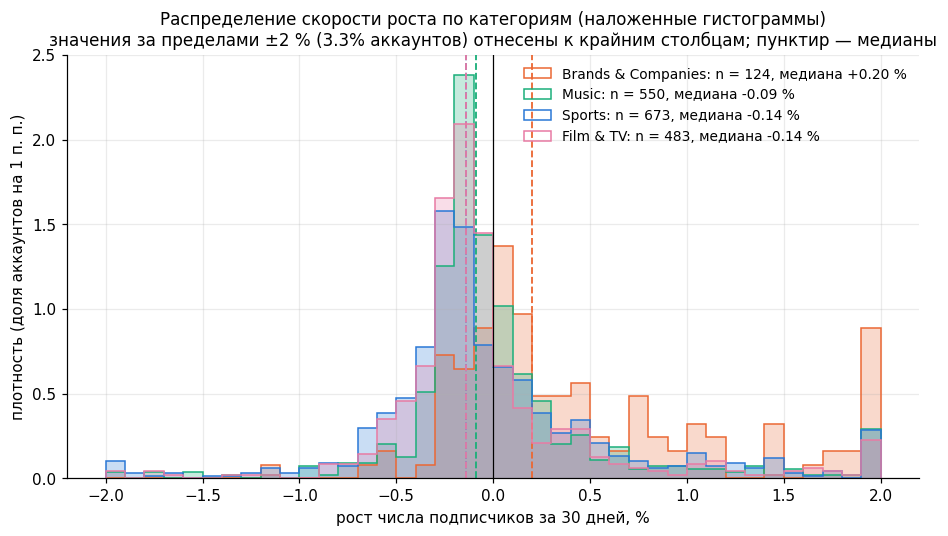

In [ ]:
acc = (ig.groupby("username")
         .agg(first=("followers", "first"), last=("followers", "last"),
              d0=("date", "first"), d1=("date", "last"), n_obs=("date", "nunique"),
              category=("category", "first"), type=("type", "first"), country=("country", "first")))
acc["days"] = (acc["d1"] - acc["d0"]).dt.days
acc = acc[acc["days"] >= 14].copy()
acc["g30"] = ((acc["last"] / acc["first"]) ** (30 / acc["days"]) - 1) * 100
print("Аккаунтов с периодом наблюдения >= 14 дней:", len(acc))

stats_cat = (acc.groupby("category")["g30"]
               .agg(аккаунтов="count", медиана="median", среднее="mean",
                    доля_растущих=lambda s: (s > 0).mean() * 100)
               .sort_values("медиана", ascending=False))
display(stats_cat.round(3))

CATS = ["Brands & Companies", "Music", "Sports", "Film & TV"]
cat_colors = dict(zip(CATS, [C["orange"], C["aqua"], C["blue"], C["magenta"]]))
bins = np.linspace(-2, 2, 41)                      # шаг 0,1 п. п.
fig, ax = plt.subplots(figsize=(10, 5))
for cat in CATS:
    v = acc.loc[acc["category"] == cat, "g30"]
    ax.hist(v.clip(bins[0], bins[-1]), bins=bins, density=True, histtype="stepfilled",
            alpha=0.25, color=cat_colors[cat])
    ax.hist(v.clip(bins[0], bins[-1]), bins=bins, density=True, histtype="step", lw=1.8,
            color=cat_colors[cat], label=f"{cat}: n = {len(v)}, медиана {v.median():+.2f} %")
    ax.axvline(v.median(), color=cat_colors[cat], ls="--", lw=1.2)
ax.axvline(0, color="black", lw=0.8)
outside = ((acc.loc[acc["category"].isin(CATS), "g30"].abs() > 2).mean())
ax.set(xlabel="рост числа подписчиков за 30 дней, %", ylabel="плотность (доля аккаунтов на 1 п. п.)",
       title=f"Распределение скорости роста по категориям (наложенные гистограммы)\n"
             f"значения за пределами ±2 % ({outside:.1%} аккаунтов) отнесены к крайним столбцам; пунктир — медианы")
ax.legend(frameon=False, fontsize=9)
plt.show()

### 3.5. Вопрос 3: размер аккаунта и скорость роста
Делим аккаунты на пять равных по численности групп по числу подписчиков в начале наблюдения (`pd.qcut`) и сравниваем медианный рост; на диаграмме рассеяния ось x — логарифмическая (размеры аккаунтов различаются на два порядка). Связь оцениваем ранговым коэффициентом корреляции Спирмена: он не чувствителен к выбросам и к нелинейности.

,аккаунтов,подписчиков_от_млн,подписчиков_до_млн,медиана_роста,доля_растущих
0,432,0.25,3.07,-0.06,45.83
1,432,3.10,6.59,-0.04,47.45
2,431,6.60,10.79,-0.11,40.37
3,432,10.79,19.47,-0.11,36.57
4,432,19.48,686.69,-0.10,34.95


Коэффициент Спирмена (все): -0.047; люди: -0.009; организации: -0.131


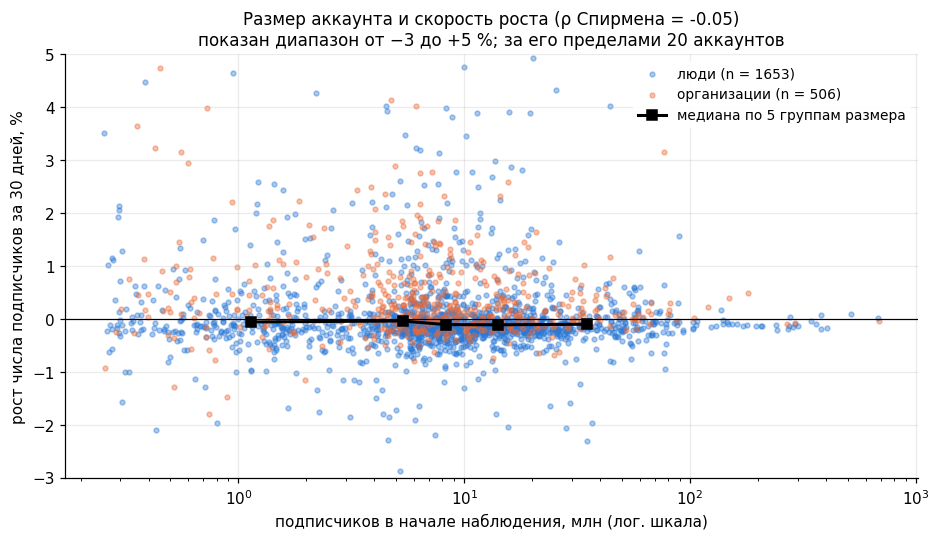

Самые быстрорастущие аккаунты:


,category,type,first,last,days,g30
username,,,,,,
lulaoficial,Public figures,person,15499325,20297019,30,30.95
teslamotors,Brands & Companies,org,9541172,11357591,26,22.27
missgrandinternational,Fashion & beauty,org,6326794,7210716,20,21.67
bryancranston,Film & TV,person,6144540,6694481,17,16.33
realbarbarapalvin,Film & TV,person,21500011,24144692,28,13.24


In [ ]:
acc["группа по размеру"] = pd.qcut(acc["first"], 5)
size_tab = acc.groupby("группа по размеру", observed=True).agg(
    аккаунтов=("g30", "size"), подписчиков_от_млн=("first", lambda s: s.min() / 1e6),
    подписчиков_до_млн=("first", lambda s: s.max() / 1e6), медиана_роста=("g30", "median"),
    доля_растущих=("g30", lambda s: (s > 0).mean() * 100))
display(size_tab.round(2).reset_index(drop=True))

rho = acc["first"].corr(acc["g30"], method="spearman")
rho_t = {t: acc.loc[acc["type"] == t, "first"].corr(acc.loc[acc["type"] == t, "g30"], method="spearman")
         for t in ["person", "org"]}
print(f"Коэффициент Спирмена (все): {rho:.3f}; люди: {rho_t['person']:.3f}; организации: {rho_t['org']:.3f}")

fig, ax = plt.subplots(figsize=(10, 5))
for t, lab, col in [("person", "люди", C["blue"]), ("org", "организации", C["orange"])]:
    part = acc[acc["type"] == t]
    ax.scatter(part["first"] / 1e6, part["g30"], s=10, alpha=0.4, color=col, label=f"{lab} (n = {len(part)})")
centers = acc.groupby("группа по размеру", observed=True)["first"].median() / 1e6
ax.plot(centers, size_tab["медиана_роста"], "-s", color="black", lw=2, ms=6, label="медиана по 5 группам размера")
ax.axhline(0, color="black", lw=0.8)
ax.set_xscale("log")
ylim = (-3, 5)
hidden = ((acc["g30"] < ylim[0]) | (acc["g30"] > ylim[1])).sum()
ax.set(ylim=ylim, xlabel="подписчиков в начале наблюдения, млн (лог. шкала)",
       ylabel="рост числа подписчиков за 30 дней, %",
       title=f"Размер аккаунта и скорость роста (ρ Спирмена = {rho:.2f})\n"
             f"показан диапазон от −3 до +5 %; за его пределами {hidden} аккаунтов")
ax.legend(fontsize=9, loc="upper right", framealpha=0.95, edgecolor="none")
plt.show()

print("Самые быстрорастущие аккаунты:")
display(acc.nlargest(5, "g30")[["category", "type", "first", "last", "days", "g30"]].round(2))

### 3.6. Выводы по части 3

1. **В октябре 2026 г. аудитория звёзд медленно сокращалась, а у организаций росла** (вопрос 1, линейный график). Падение у людей идёт плавно каждый день, а не одним скачком.
2. **Категории различаются направлением роста** (вопрос 2, наложенные гистограммы). Медианный рост за 30 дней: Brands & Companies +0,20 %, Media +0,38 %, Public figures +0,18 % — против Music −0,09 %, Sports −0,14 %, Film & TV −0,14 %. Растут 73 % брендов и только 29 % аккаунтов кино и ТВ. Распределение брендов сдвинуто вправо и имеет длинный «хвост» быстрого роста, а у спорта, музыки и кино основная масса лежит чуть левее нуля.
3. **Размер аккаунта со скоростью роста почти не связан** (вопрос 3, диаграмма рассеяния). Коэффициент Спирмена −0,05; медианный рост в пяти группах по размеру — от −0,04 % до −0,11 %. Есть лишь слабая тенденция: доля растущих аккаунтов снижается от 46 % в самой маленькой группе до 35 % в самой крупной.
4. **Изменения в целом очень малы, кроме отдельных событий.** У половины аккаунтов рост за 30 дней лежит в узком интервале от −0,24 % до +0,23 % (25-й и 75-й процентили), но единичные аккаунты растут на десятки процентов: `lulaoficial` +31 %, `teslamotors` +22 %, `missgrandinternational` +22 %. Такие всплески, вероятно, связаны с событиями а не с общим трендом.
5. **Что требует дополнительной проверки.** (а) Снижение аудитории у людей может объясняться не потерей интереса, а чисткой ботов и неактивных аккаунтов Instagram; данные этого не различают. (б) Период — всего 36 дней, поэтому выводы о тенденциях предварительные. (в) Сборщик каждый день обновляет только часть аккаунтов, и неизвестно, как он их выбирает: если чаще обновляются «активные» аккаунты, выборка смещена. (г) Объяснение всплесков событиями — предположение, его нужно проверить по датам новостей.